# Session 12: How well does ERA5 locate ice-supersaturated air? A check against IAGOS

**Question:** at cruise levels over the study region, how often does ERA5, as used in this project, put ice-supersaturated air (and persistent-contrail conditions) where aircraft actually measured it, and does moving the ERA5 field up or down (the height errors assumed in Sessions 7–11) make it agree better?

**Builds on:** Sessions 7–11 assumed that ERA5 may place the moist layer 150–600 m too high or too low, with each error equally likely, and found that these height errors change route choices on most nights. That assumption is tested here.

**Data:** IAGOS-CORE L2 time series for 2022 (In-service Aircraft for a Global Observing System): relative humidity over ice (RHI) and temperature measured every 4 s on board passenger airliners, quality controlled by the IAGOS data centre. 971 flights were downloaded on 4 November 2026 for 40–60°N, 20°W–20°E; the data stay outside the repository and only summary results are saved here.

**Approach:**
1. Keep the measurements inside the study region (15°W–15°E, 40–60°N) at 175–300 hPa (the ERA5 levels of the route evaluation).
2. Match ERA5 to every measurement with the route evaluation's own steps (`scripts/match_era5_to_iagos.py`): same loader and checks, same 10 pressure levels, interpolation in space and time, pycontrails' PCR model, in the field as given and in the six shifted fields.
3. Compute ice supersaturation (ISSR) and persistent-contrail conditions (PCR) from the measured temperature and humidity with the same pycontrails model and parameters.
4. Compare: how much measured ice supersaturation ERA5 finds (hit rate), how much of ERA5's is real (false alarm ratio), and skill beyond chance (equitable threat score).

**Rules fixed before any comparison was made** (changes after seeing results are listed under Deviations in the Results):
- Measurements used only where IAGOS flags pressure, temperature and RHI as good and RHI as final. Temperature from the humidity package (P1), as IAGOS uses it to derive RHI.
- Measured ice supersaturation: RHI > 1, evaluated by pycontrails' ISSR model. Sensitivity case: RHI > 1 + IAGOS's own error estimate for that point.
- ERA5 unscaled (as in the route evaluation's base case), interpolated linearly between the two hours around each measurement.
- Height test only at 195–270 hPa, where every shifted field still covers the point.
- Flights are the independent units: 95% intervals by resampling whole flights (1,000 resamples, seed 0).
- Best shift: for every 10 minutes of one flight with ice supersaturation in the measurement or in any shifted field, the shift whose ISSR agrees with the measurement at the most points; ties go to the smaller shift, and no shift first. Blocks where every field agrees equally (for example, measured ice supersaturation that no field has at all) say nothing about height: they are counted separately and left out of the weights.
- Matching runs until every hour is done or for at most three nights, whichever comes first. All matched hours are used; days were matched in a fixed random order, so a partial run is still a sample spread over the year, and the share matched is reported.

**Assumptions and limits:** a measurement is a point, ERA5 a ~25 km box average, so some disagreement is expected even from a perfect model. IAGOS's own RHI error estimate is about 0.13 near saturation. Four aircraft based at Frankfurt and Paris, so the sample favours their routes and times. March and April have few flights.

**Sections:** 1. Setup · 2. The measurements · 3. Matching status · 4. Checks · 5. Does ERA5 find the ice-supersaturated air? · 6. Is the moist layer at the wrong height? · 7. How dry is ERA5 where the air is supersaturated? · 8. Figures · Results

## 1. Setup

Run `scripts/match_era5_to_iagos.py` first (instructions at the top of the script). The IAGOS folder defaults to `iagos_data` in your home folder; set the environment variable `IAGOS_DATA` to use another.

In [1]:
import os, sys, time, warnings
from pathlib import Path
SRC = (Path("..") / "src").resolve()
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from contrail_routing import config
from contrail_routing.iagos import (VERTICAL_M, SHIFT_ORDER, observed_pcr, bootstrap_scores,
                                    best_shift, hour_windows)

warnings.filterwarnings("ignore", message=r"\s*Met data appears to have originated from ECMWF")
pd.set_option("display.width", 220)

DATA_DIR = Path(os.environ.get("IAGOS_DATA", Path.home() / "iagos_data"))
MATCHED = DATA_DIR / "matched"
results_dir = Path("..") / "results"
fig_dir, s12_dir = results_dir / "figures", results_dir / "session12"
s12_dir.mkdir(parents=True, exist_ok=True)

P_HEIGHT_TEST = (195.0, 270.0)     # every shifted field covers these pressures
N_BOOT, SEED = 1000, 0
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}

points = pd.read_pickle(MATCHED / "iagos_points.pkl")
flights = pd.read_csv(MATCHED / "iagos_flights.csv")
print(f"IAGOS folder: {DATA_DIR}")
print(f"{len(flights)} flight files; {len(points):,} good points in the region at 175-300 hPa from "
      f"{points['flight_id'].nunique()} flights")

IAGOS folder: C:\Users\barqb\iagos_data
971 flight files; 786,845 good points in the region at 175-300 hPa from 833 flights


## 2. The measurements

What was measured, before any comparison: where, when, and how often the air was ice-supersaturated. The measured ISSR and PCR use pycontrails with the measured temperature and humidity.

In [2]:
t0 = time.time()
obs = observed_pcr(points)
pts = pd.concat([points, obs], axis=1)
pts["month"] = pts["time"].dt.month
pts["season"] = pts["month"].map(SEASON)
pts["iss_confident"] = (pts["rhi"] > 1 + pts["rhi_err"]).astype(float)
print(f"Measured SAC/ISSR/PCR for {len(pts):,} points in {time.time() - t0:.0f} s")

print(f"\nFlying time: {len(pts) * 4 / 3600:,.0f} h | flights: {pts['flight_id'].nunique()} | "
      f"aircraft: {flights['platform'].str.split(',').str[3].str.strip().nunique()}")
print("Points by phase:", pts["phase"].value_counts().to_dict())
by_month = pts.groupby("month").agg(points=("rhi", "size"), flights=("flight_id", "nunique"),
                                    issr_share=("issr_obs", "mean"), pcr_share=("pcr_obs", "mean"))
print("\nBy month:")
print(by_month.round(3).to_string())
print(f"\nMeasured shares: ice-supersaturated {pts['issr_obs'].mean():.3f}, SAC met {pts['sac_obs'].mean():.3f}, "
      f"persistent-contrail conditions {pts['pcr_obs'].mean():.3f}, confidently supersaturated (RHI > 1 + error) "
      f"{pts['iss_confident'].mean():.3f}")
print("IAGOS RHI error estimate (median) by RHI:",
      pts.groupby(pd.cut(pts["rhi"], [0, 0.5, 0.9, 1.1, 2.0]), observed=True)["rhi_err"].median().round(3).to_dict())
by_month.to_csv(s12_dir / "measurements_by_month.csv")

Measured SAC/ISSR/PCR for 786,845 points in 0 s

Flying time: 874 h | flights: 833 | aircraft: 5
Points by phase: {'cruise': 672261, 'ascent': 66329, 'descent': 48255}

By month:
       points  flights  issr_share  pcr_share
month                                        
1       17464       16       0.136      0.136
2       24755       22       0.101      0.101
3       10981        7       0.005      0.005
4        5841        7       0.063      0.063
5       33144       35       0.191      0.188
6       43914       50       0.064      0.046
7      155733      173       0.061      0.052
8      130615      156       0.088      0.073
9      120515      125       0.150      0.133
10      43351       47       0.220      0.151
11     119096      128       0.128      0.125
12      81436       67       0.094      0.094

Measured shares: ice-supersaturated 0.109, SAC met 0.601, persistent-contrail conditions 0.097, confidently supersaturated (RHI > 1 + error) 0.042
IAGOS RHI error estimate (med

## 3. Matching status

ERA5 values come from the matching script, one file per hour. A partial run is usable (days were processed in a fixed random order), but the share matched is part of the result.

In [3]:
windows = hour_windows(points["time"])
files = sorted((MATCHED / "era5").glob("*.csv"))
print(f"Hours matched: {len(files)} of {len(windows)} ({100 * len(files) / len(windows):.1f}%)")
t0 = time.time()
era5 = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)
df = pts.merge(era5, on="point_id", how="inner", validate="one_to_one")
print(f"Read {len(era5):,} matched points in {time.time() - t0:.0f} s; joined: {len(df):,} points from "
      f"{df['flight_id'].nunique()} flights ({100 * len(df) / len(pts):.1f}% of all points)")
print("Matched points by season:", df["season"].value_counts().to_dict())
log = MATCHED / "match_log.csv"
if log.exists():
    lg = pd.read_csv(log)
    print("Matching log:", lg["status"].value_counts().to_dict(), f"| {lg['minutes'].sum() / 60:.1f} h of matching")

Hours matched: 1480 of 1480 (100.0%)
Read 786,845 matched points in 15 s; joined: 786,845 points from 833 flights (100.0% of all points)
Matched points by season: {'JJA': 330262, 'SON': 282962, 'DJF': 123655, 'MAM': 49966}
Matching log: {'ok': 252} | 23.9 h of matching


## 4. Checks

If the matching is right, ERA5 temperature should agree with the measured temperature to about a kelvin; a large bias would mean a mismatch in time, position or pressure, not a humidity problem. Missing ERA5 values are expected only for shifted fields at the edges of the pressure range.

In [4]:
dT = df["T_base"] - df["T_K"]
print(f"ERA5 minus measured temperature (K): mean {dT.mean():+.2f}, median {dT.median():+.2f}, "
      f"sd {dT.std():.2f}, 1st-99th percentile {dT.quantile(0.01):+.2f} to {dT.quantile(0.99):+.2f}")
print("By season (mean, K):", df.assign(dT=dT).groupby("season")["dT"].mean().round(2).to_dict())
nan_share = {s: round(float(df[f"rhi_{s}"].isna().mean()), 4) for s in SHIFT_ORDER}
print("Share of points without an ERA5 value, by field:", nan_share)
h = df[df["p_hPa"].between(*P_HEIGHT_TEST)]
print(f"Height-test points ({P_HEIGHT_TEST[0]:.0f}-{P_HEIGHT_TEST[1]:.0f} hPa): {len(h):,}; "
      f"with a value in every field: {int(h[[f'rhi_{s}' for s in SHIFT_ORDER]].notna().all(axis=1).sum()):,}")
print("\nERA5 RHi vs measured RHI (median ERA5 by measured bin):")
print(df.groupby(pd.cut(df["rhi"], [0, 0.3, 0.6, 0.9, 1.0, 1.1, 1.2, 2.0]), observed=True)
        .agg(points=("rhi", "size"), era5_rhi_median=("rhi_base", "median")).round(3).to_string())
pd.DataFrame({"mean_K": [dT.mean()], "median_K": [dT.median()], "sd_K": [dT.std()]}).to_csv(
    s12_dir / "temperature_check.csv", index=False)

ERA5 minus measured temperature (K): mean -0.48, median -0.50, sd 0.80, 1st-99th percentile -2.68 to +1.63
By season (mean, K): {'DJF': -0.43, 'JJA': -0.5, 'MAM': -0.47, 'SON': -0.49}
Share of points without an ERA5 value, by field: {'base': 0.0, 'up150': 0.0081, 'down150': 0.0141, 'up300': 0.0278, 'down300': 0.0144, 'up600': 0.0689, 'down600': 0.1487}
Height-test points (195-270 hPa): 612,557; with a value in every field: 612,557

ERA5 RHi vs measured RHI (median ERA5 by measured bin):
            points  era5_rhi_median
rhi                                
(0.0, 0.3]  342824            0.104
(0.3, 0.6]  177602            0.430
(0.6, 0.9]  138161            0.711
(0.9, 1.0]   40183            0.906
(1.0, 1.1]   41254            0.970
(1.1, 1.2]   27181            1.002
(1.2, 2.0]   17429            1.011


## 5. Does ERA5 find the ice-supersaturated air?

ERA5 in the field as given, all matched points at 175–300 hPa. Hit rate = share of measured events that ERA5 also has; false alarm ratio = share of ERA5's events that were not measured; ETS = skill beyond chance (0 = none, 1 = perfect). Intervals: 95%, resampling whole flights.

In [5]:
def score_row(d, obs_col, mod_col, **labels):
    s = bootstrap_scores(d, obs_col, mod_col, n_boot=N_BOOT, seed=SEED)
    row = {**labels, "points": s["n_points"], "flights": s["n_units"]}
    for k in ("observed_share", "model_share", "hit_rate", "false_alarm_ratio", "ets"):
        row[k], row[k + "_lo"], row[k + "_hi"] = s[k]
    return row

rows = [score_row(df, "issr_obs", "issr_base", what="ISSR", subset="all"),
        score_row(df, "pcr_obs", "pcr_base", what="PCR", subset="all"),
        score_row(df, "iss_confident", "issr_base", what="ISSR (RHI > 1 + error)", subset="all")]
for season in ["DJF", "MAM", "JJA", "SON"]:
    rows.append(score_row(df[df["season"] == season], "issr_obs", "issr_base", what="ISSR", subset=season))
for phase in ["cruise", "ascent", "descent"]:
    rows.append(score_row(df[df["phase"] == phase], "issr_obs", "issr_base", what="ISSR", subset=phase))
base_scores = pd.DataFrame(rows)

def fmt(r, k):
    return f"{r[k]:.2f} [{r[k + '_lo']:.2f}-{r[k + '_hi']:.2f}]"
show = base_scores[["what", "subset", "points", "flights"]].copy()
for k in ("observed_share", "model_share", "hit_rate", "false_alarm_ratio", "ets"):
    show[k] = [fmt(r, k) for _, r in base_scores.iterrows()]
print(show.to_string(index=False))
base_scores.to_csv(s12_dir / "scores_base.csv", index=False)

                  what  subset  points  flights   observed_share      model_share         hit_rate false_alarm_ratio              ets
                  ISSR     all  786845      833 0.11 [0.09-0.12] 0.09 [0.08-0.11] 0.47 [0.43-0.51]  0.46 [0.41-0.51] 0.29 [0.26-0.32]
                   PCR     all  786845      833 0.10 [0.08-0.11] 0.08 [0.07-0.09] 0.47 [0.42-0.51]  0.46 [0.40-0.51] 0.29 [0.26-0.33]
ISSR (RHI > 1 + error)     all  786845      833 0.04 [0.03-0.05] 0.09 [0.08-0.11] 0.57 [0.51-0.62]  0.75 [0.70-0.79] 0.18 [0.15-0.22]
                  ISSR     DJF  123655      105 0.10 [0.06-0.15] 0.10 [0.07-0.14] 0.65 [0.57-0.71]  0.35 [0.21-0.51] 0.44 [0.34-0.52]
                  ISSR     MAM   49966       49 0.14 [0.08-0.20] 0.10 [0.06-0.14] 0.48 [0.39-0.57]  0.35 [0.19-0.55] 0.33 [0.24-0.41]
                  ISSR     JJA  330262      379 0.07 [0.05-0.09] 0.07 [0.05-0.08] 0.42 [0.35-0.49]  0.54 [0.45-0.63] 0.25 [0.19-0.31]
                  ISSR     SON  282962      300 0.15 [0.12-0.1

## 6. Is the moist layer at the wrong height?

The same scores for each shifted field, on the points that every field covers (195–270 hPa). If ERA5's errors were mainly in the height of the layer, some shifted field would agree clearly better than the field as given. Then, for every 10 minutes of flying with ice supersaturation in the measurement or in any field, the shift that agrees best: these shares are measured weights that can replace the equal weights of Sessions 7–11.

In [6]:
ht = df[df["p_hPa"].between(*P_HEIGHT_TEST)].dropna(subset=[f"issr_{s}" for s in SHIFT_ORDER])
shift_rows = [score_row(ht, "issr_obs", f"issr_{s}", what="ISSR", subset=s) | {"shift_m": VERTICAL_M[s]}
              for s in SHIFT_ORDER]
shift_scores = pd.DataFrame(shift_rows).sort_values("shift_m")
show = shift_scores[["subset", "shift_m"]].rename(columns={"subset": "field"}).copy()
for k in ("model_share", "hit_rate", "false_alarm_ratio", "ets"):
    show[k] = [fmt(r, k) for _, r in shift_scores.iterrows()]
print(f"Height-test points: {len(ht):,} from {ht['flight_id'].nunique()} flights; measured ISSR share {ht['issr_obs'].mean():.3f}")
print(show.to_string(index=False))

blocks = best_shift(ht)
inf = blocks[blocks["informative"]]
w = inf["best"].value_counts(normalize=True).reindex(SHIFT_ORDER).fillna(0.0)
w_meas = inf.loc[inf["obs_share"] > 0, "best"].value_counts(normalize=True).reindex(SHIFT_ORDER).fillna(0.0)
weights = pd.DataFrame({"shift_m": [VERTICAL_M[s] for s in SHIFT_ORDER],
                        "share_of_blocks": w.values, "share_of_blocks_with_measured_ISS": w_meas.values},
                       index=SHIFT_ORDER).sort_values("shift_m")
print(f"\n10-minute blocks with ice supersaturation somewhere: {len(blocks):,} from {blocks['flight_id'].nunique()} flights; "
      f"informative about height (fields disagree): {len(inf):,} ({100 * len(inf) / len(blocks):.1f}%)")
print("Best-agreeing shift (share of informative blocks):")
print(weights.round(3).to_string())
wm = blocks[blocks["obs_share"] > 0]
print(f"\nBlocks with measured ice supersaturation: {len(wm):,}; of these, no field (shifted or not) has any: "
      f"{int(wm['missed_by_all'].sum()):,} ({100 * wm['missed_by_all'].mean():.1f}%)")
print(f"Informative blocks, median agreement: best field {inf['best_agreement'].median():.3f}, "
      f"field as given {inf['agree_base'].median():.3f}")
shift_scores.to_csv(s12_dir / "scores_by_shift.csv", index=False)
weights.to_csv(s12_dir / "best_shift_weights.csv")

Height-test points: 612,557 from 810 flights; measured ISSR share 0.117
  field  shift_m      model_share         hit_rate false_alarm_ratio              ets
down600   -600.0 0.06 [0.05-0.07] 0.28 [0.23-0.33]  0.43 [0.36-0.51] 0.19 [0.16-0.23]
down300   -300.0 0.08 [0.07-0.09] 0.39 [0.34-0.43]  0.43 [0.36-0.49] 0.25 [0.22-0.29]
down150   -150.0 0.09 [0.08-0.11] 0.44 [0.40-0.48]  0.45 [0.39-0.51] 0.27 [0.24-0.31]
   base      0.0 0.10 [0.09-0.11] 0.46 [0.42-0.50]  0.46 [0.40-0.52] 0.28 [0.25-0.31]
  up150    150.0 0.11 [0.10-0.12] 0.49 [0.45-0.54]  0.48 [0.42-0.54] 0.29 [0.25-0.32]
  up300    300.0 0.12 [0.10-0.13] 0.48 [0.44-0.53]  0.51 [0.46-0.57] 0.26 [0.23-0.30]
  up600    600.0 0.13 [0.12-0.14] 0.45 [0.41-0.49]  0.59 [0.55-0.64] 0.21 [0.18-0.24]

10-minute blocks with ice supersaturation somewhere: 1,520 from 458 flights; informative about height (fields disagree): 1,264 (83.2%)
Best-agreeing shift (share of informative blocks):
         shift_m  share_of_blocks  share_of_blocks_wi

## 7. How dry is ERA5 where the air is supersaturated?

Where the measured air is ice-supersaturated, the distribution of ERA5's RHi at the same place and time: a model that finds the layer but underestimates its humidity would show values just below 1; one that misses the layer, much lower values.

In [7]:
iss = df[df["issr_obs"] > 0.5]
q = iss["rhi_base"].quantile([0.1, 0.25, 0.5, 0.75, 0.9])
print(f"ERA5 RHi where the measured air is supersaturated ({len(iss):,} points): "
      + ", ".join(f"p{int(k * 100)} {v:.2f}" for k, v in q.items()))
print("Share of these points where ERA5 RHi is ...",
      {f">= {x}": round(float((iss['rhi_base'] >= x).mean()), 3) for x in (1.0, 0.95, 0.9, 0.8)})
print(f"Measured RHI at these points: median {iss['rhi'].median():.2f}; ERA5 minus measured RHi: median "
      f"{(iss['rhi_base'] - iss['rhi']).median():+.2f}")
bins = np.round(np.arange(0.0, 1.61, 0.1), 2)
dry = (df.groupby(pd.cut(df["rhi"], bins), observed=True)
         .agg(points=("rhi", "size"), era5_median=("rhi_base", "median"),
              era5_p25=("rhi_base", lambda x: x.quantile(0.25)), era5_p75=("rhi_base", lambda x: x.quantile(0.75))))
dry.to_csv(s12_dir / "era5_rhi_by_measured_rhi.csv")

ERA5 RHi where the measured air is supersaturated (85,864 points): p10 0.76, p25 0.90, p50 0.99, p75 1.04, p90 1.09
Share of these points where ERA5 RHi is ... {'>= 1.0': 0.469, '>= 0.95': 0.655, '>= 0.9': 0.748, '>= 0.8': 0.869}
Measured RHI at these points: median 1.10; ERA5 minus measured RHi: median -0.15


## 8. Figures

Left: hit rate and false alarm ratio of ERA5 ice supersaturation for each vertical shift, with 95% intervals. Middle: the best-agreeing shift per 10 minutes of flying with ice supersaturation, against the equal weights assumed so far. Right: ERA5 RHi against measured RHI (all matched points).

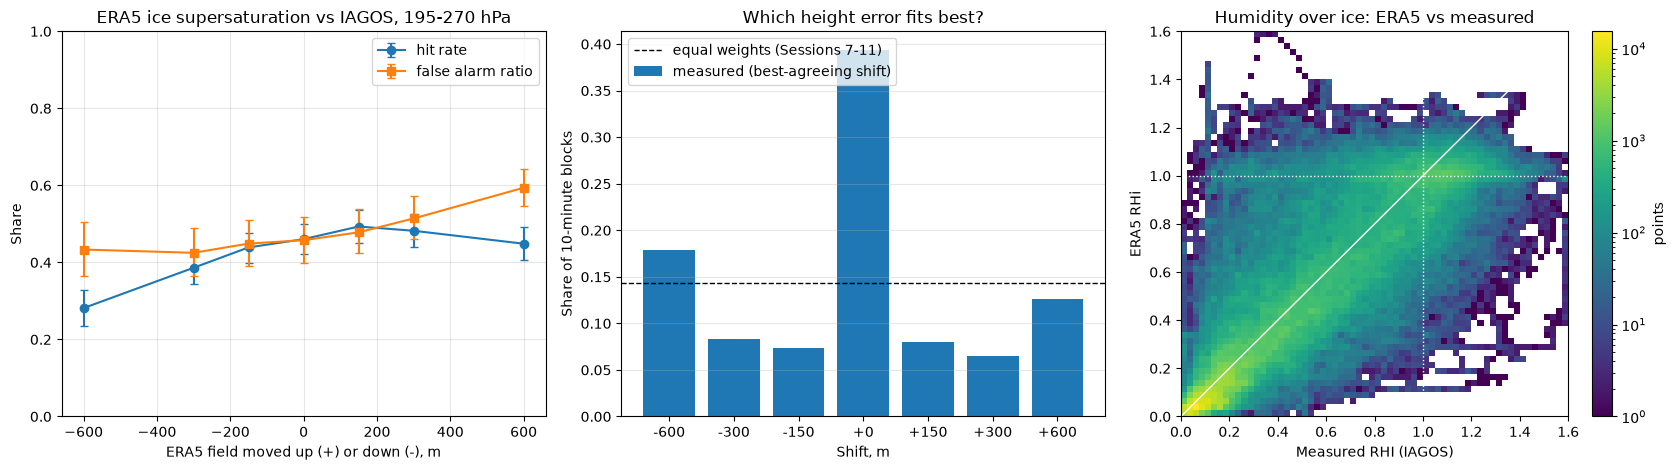

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
x = shift_scores["shift_m"].to_numpy()
for k, lab, mk in [("hit_rate", "hit rate", "o"), ("false_alarm_ratio", "false alarm ratio", "s")]:
    y = shift_scores[k].to_numpy()
    err = np.vstack([y - shift_scores[k + "_lo"], shift_scores[k + "_hi"] - y])
    ax.errorbar(x, y, yerr=err, marker=mk, capsize=3, label=lab)
ax.set_xlabel("ERA5 field moved up (+) or down (-), m")
ax.set_ylabel("Share")
ax.set_title("ERA5 ice supersaturation vs IAGOS, 195-270 hPa")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

ax = axes[1]
xs = np.arange(len(weights))
ax.bar(xs, weights["share_of_blocks"], color="tab:blue", label="measured (best-agreeing shift)")
ax.axhline(1 / len(weights), color="k", ls="--", lw=1, label="equal weights (Sessions 7-11)")
ax.set_xticks(xs)
ax.set_xticklabels([f"{v:+.0f}" for v in weights["shift_m"]])
ax.set_xlabel("Shift, m")
ax.set_ylabel("Share of 10-minute blocks")
ax.set_title("Which height error fits best?")
ax.legend(loc="upper left")
ax.grid(alpha=0.3, axis="y")

ax = axes[2]
hb = ax.hist2d(df["rhi"].clip(0, 1.6), df["rhi_base"].clip(0, 1.6), bins=64, range=[[0, 1.6], [0, 1.6]],
               cmap="viridis", norm=plt.matplotlib.colors.LogNorm())
ax.plot([0, 1.6], [0, 1.6], color="w", lw=1)
ax.axvline(1, color="w", ls=":", lw=1)
ax.axhline(1, color="w", ls=":", lw=1)
fig.colorbar(hb[3], ax=ax, label="points")
ax.set_xlabel("Measured RHI (IAGOS)")
ax.set_ylabel("ERA5 RHi")
ax.set_title("Humidity over ice: ERA5 vs measured")
fig.tight_layout()
fig.savefig(fig_dir / "session12_era5_vs_iagos.png", dpi=150, bbox_inches="tight")
plt.show()

## Results
 
### Setup
 
IAGOS-CORE L2 measurements from 2022 inside the study region (15°W–15°E, 40–60°N) at 175–300 hPa: **786,845 points from 833 flights** (874 hours of flying). The flights come from 4 aircraft, 3 Lufthansa and 1 Air France, based at Frankfurt and Paris; one further flight has an incomplete aircraft record, which is why the notebook counts 5. 85% of the points are at cruise and 15% in climb or descent. ERA5 was matched to every point by `scripts/match_era5_to_iagos.py`: all 1,480 hourly windows on 252 days, in 23.9 hours, with no failed days. ERA5 went through the route evaluation's own steps, in the field as given and in the six height-shifted fields of Sessions 7–11. Coverage is uneven: July–September and November give most of the data, and March and April have only 7 flights each.
 
### Checks
 
- **The matching is right.** ERA5 minus measured temperature: mean −0.48 K, sd 0.80 K, 98% of points within −2.7 to +1.6 K, and the same in every season (−0.43 to −0.50 K). A mismatch in time, position or pressure would show as errors of several kelvin.
- **Every point has a value in the field as given.** Shifted fields lose points only at the edges of the pressure range, as expected: up to 15% for the field moved down 600 m. Every point in the 195–270 hPa height test (612,557) has a value in all seven fields.
- **The measurements look as expected.** 10.9% of the measured points are ice-supersaturated. PCR conditions are measured at 9.7% of points: most supersaturated air is also cold enough for contrails to form, although the Schmidt–Appleman criterion is met at only 60% of all points. IAGOS's own RHI error estimate is about 0.13 near saturation, and only 4.2% of points are supersaturated by more than that error.
- **Matched humidity follows the measurement:** ERA5's median RHi rises from 0.10 to 1.01 across the bins of measured RHI.
- **Deviations from the rules fixed in advance:** none.
### Findings
 
#### 1. ERA5 finds about half of the ice-supersaturated air, and about half of what it shows is real
 
All matched points, field as given. Values are given with 95% intervals from resampling whole flights.
 
| Subset | Measured share | ERA5 share | Hit rate | False alarm ratio | ETS |
|---|---|---|---|---|---|
| ISSR, all points | 0.11 | 0.09 | 0.47 [0.43–0.51] | 0.46 [0.41–0.51] | 0.29 [0.26–0.32] |
| PCR, all points | 0.10 | 0.08 | 0.47 [0.42–0.51] | 0.46 [0.40–0.51] | 0.29 [0.26–0.33] |
| ISSR, cruise only | 0.10 | 0.09 | 0.47 [0.43–0.51] | 0.43 [0.36–0.49] | 0.30 [0.27–0.34] |
| ISSR, winter (DJF) | 0.10 | 0.10 | 0.65 [0.57–0.71] | 0.35 [0.21–0.51] | 0.44 [0.34–0.52] |
| ISSR, spring (MAM) | 0.14 | 0.10 | 0.48 [0.39–0.57] | 0.35 [0.19–0.55] | 0.33 [0.24–0.41] |
| ISSR, summer (JJA) | 0.07 | 0.07 | 0.42 [0.35–0.49] | 0.54 [0.45–0.63] | 0.25 [0.19–0.31] |
| ISSR, autumn (SON) | 0.15 | 0.13 | 0.44 [0.39–0.50] | 0.46 [0.40–0.54] | 0.25 [0.21–0.30] |
 
- ERA5 gets the *amount* of ice-supersaturated air about right (9% against 11%) but often puts it in the wrong place. The skill is clearly above chance (ETS 0.29) and far from perfect.
- For contrails (PCR), the scores are the same as for ice supersaturation: the temperature part of the problem adds almost no error, as the temperature check suggests.
- ERA5 does best in winter (hit rate 0.65, ETS 0.44) and worst in summer and autumn (ETS 0.25).
- Sensitivity case (rules): counting only air supersaturated by more than IAGOS's error estimate, ERA5 finds more of it (hit rate 0.57 [0.51–0.62]). The false alarm ratio rises to 0.75 by construction, because the measured events are rarer.
#### 2. Most misses are ERA5 being too dry near saturation, not missing the moist air altogether
 
- Where the measured air is supersaturated (85,864 points), ERA5's RHi has a median of **0.99** (10th–90th percentile 0.76–1.09), against a measured median of 1.10. ERA5 is at or above saturation at 47% of these points, at 0.95 or more at 66%, and at 0.8 or more at 87%.
- The ERA5 minus measured RHi is a median −0.15 at these points, and ERA5's values pile up near 1.0 (right panel of the figure).
- In 24% of the 10-minute blocks with measured ice supersaturation, *no* field, shifted or not, has any. No height correction can fix those.
#### 3. No sign of a systematic height error, but large errors do happen
 
Test points at 195–270 hPa (612,557 points, 810 flights; measured share 0.117):
 
| ERA5 field | ERA5 share | Hit rate | False alarm ratio | ETS |
|---|---|---|---|---|
| moved down 600 m | 0.06 | 0.28 [0.23–0.33] | 0.43 [0.36–0.51] | 0.19 [0.16–0.23] |
| moved down 300 m | 0.08 | 0.39 [0.34–0.43] | 0.43 [0.36–0.49] | 0.25 [0.22–0.29] |
| moved down 150 m | 0.09 | 0.44 [0.40–0.48] | 0.45 [0.39–0.51] | 0.27 [0.24–0.31] |
| as given | 0.10 | 0.46 [0.42–0.50] | 0.46 [0.40–0.52] | 0.28 [0.25–0.31] |
| moved up 150 m | 0.11 | 0.49 [0.45–0.54] | 0.48 [0.42–0.54] | 0.29 [0.25–0.32] |
| moved up 300 m | 0.12 | 0.48 [0.44–0.53] | 0.51 [0.46–0.57] | 0.26 [0.23–0.30] |
| moved up 600 m | 0.13 | 0.45 [0.41–0.49] | 0.59 [0.55–0.64] | 0.21 [0.18–0.24] |
 
- **Skill peaks at no shift or 150 m up** (ETS 0.28–0.29), with intervals that overlap: ERA5 does not place the moist air systematically too high or too low. Moving the field up adds supersaturated air at these levels, so its hits and false alarms rise together.
- **Shifts of 600 m are clearly worse on average** (ETS 0.19–0.21, intervals separate from the field as given).
- **Field by field, 10 minutes at a time** (1,520 blocks from 458 flights with ice supersaturation somewhere; 1,264 informative, i.e. fields disagree):
| Best-agreeing shift | −600 m | −300 m | −150 m | none | +150 m | +300 m | +600 m |
|---|---|---|---|---|---|---|---|
| Share of informative blocks | 0.18 | 0.08 | 0.07 | 0.39 | 0.08 | 0.07 | 0.13 |
| Share of those with measured ice supersaturation | 0.12 | 0.07 | 0.09 | 0.30 | 0.12 | 0.11 | 0.19 |
| Equal weights assumed in Sessions 7–11 | 0.14 | 0.14 | 0.14 | 0.14 | 0.14 | 0.14 | 0.14 |
 
- No shift is the most common best fit (30–39% of blocks), more often than any single shift. Shifts of 150–300 m fit best less often than the equal weights assumed, and the ±600 m shifts together fit best in about 30% of blocks.
- **Caveat:** the ±600 m columns also collect blocks where the real error is larger than 600 m, and blocks where ERA5 shows a moist layer that is not there at all, which any large shift removes. This measure cannot separate those cases, so the 600 m shares are an upper bound on 600 m height errors.
#### 4. Climbs and descents disagree in a way that points to the measurement
 
Measured ice supersaturation is 21% of points in climbs but only 3% in descents through the same levels. ERA5 shows 14% and 15%, so it sees no such difference. Moist air does not depend on the direction an aircraft flies through it. A possible cause is the humidity sensor responding slowly in cold air, so that it carries moister air from lower levels upwards in a climb and drier air downwards in a descent. This is not tested here. Climbs and descents are 15% of the points, and the main scores barely change when only cruise is used (row "ISSR, cruise only" above).
 
### What this means for the project
 
- **The height scenarios of Sessions 7–11 are not unrealistic.** Errors of up to 600 m (or more) best explain a sizeable share of the measured cases. But **no height error is the most common case**, and the equal weights over-weight the 150–300 m shifts. The worst-case and minimum-regret rules use the scenario set, not its weights, so their choices stand. A measured weighting is now available for Session 14.
- **The larger problem is humidity, not height.** Near saturation ERA5 is often slightly too dry, so it calls supersaturated air unsaturated. A height shift cannot fix that, but a humidity correction can. This is the case for Session 13: a calibrated probability of ice supersaturation from ERA5's humidity, temperature and level, trained and tested against these measurements.
### Limitations
 
- A measurement is a point and ERA5 a ~25 km box average, so part of the disagreement would remain even with a perfect model.
- Four aircraft based at Frankfurt and Paris: the sample follows their routes and times, and spring is thin (14 flights in March–April).
- The measured humidity has its own uncertainty (about ±0.13 near saturation by IAGOS's estimate), and climbs and descents show an unexplained asymmetry (finding 4).
- One year (2022), one region, and ERA5 as used here (10 pressure levels, unscaled humidity).
### Data acknowledgement
 
IAGOS-CORE L2 time series, https://doi.org/10.25326/06, from the IAGOS Data Portal (https://iagos.aeris-data.fr/), licensed under CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/). Changes made here: quality-filtered, cut to the study region and 175–300 hPa, and compared with ERA5; only summary tables are saved in the repository.
 
“MOZAIC/CARIBIC/IAGOS data were created with support from the European Commission, national agencies in Germany (BMBF), France (MESR), and the UK (NERC), and the IAGOS member institutions (http://www.iagos.org/partners). The participating airlines (Lufthansa, Air France, Austrian, China Airlines, Hawaiian Airlines, Air Canada, Iberia, Eurowings Discover, Cathay Pacific, Air Namibia, Sabena) supported IAGOS by carrying the measurement equipment free of charge since 1994. The data are available at http://www.iagos.fr thanks to additional support from AERIS.”